   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 3.4 MB/s eta 0:00:00
=== VACCINE_VIRUS_LOG v1.0 | MODE = FAST | OpenFDA-VAERS ===
  Vaccin analysé      : INFLUENZA
  Estimations         : 1 | Fenêtre : 80 rapports
  Test statistique    : cohen_d
  Seuil critique (hypothèse) : 65.0e percentile

Gradient de progression : 29 points

[1/6] Téléchargement OpenFDA VAERS (vaccin='INFLUENZA')...

[OpenFDA VAERS] Téléchargement (1000 rapports, vaccin='INFLUENZA')...
  → 1000 rapports bruts récupérés
  1000 rapports totaux → 1000 avec sériosité renseignée
[OK] 1000 rapports VAERS | Sérieux : 721 (72.1%) | Hospitalisés : 344 | Fatals : 56

[2/6] Extraction des 5 flux vaccin+virus et du score de progression immune...
  Score de progression : min=10.6 | max=98.9 | mean=50.0
  Flux actifs : ['Vaccine_Seriousness', 'Vaccine_LocalReaction', 'Age_Signal', 'Viral_Severity', 'Protection_Loss']

[3/6] Scan du seuil critique de percée virale (40–85e percentile)...


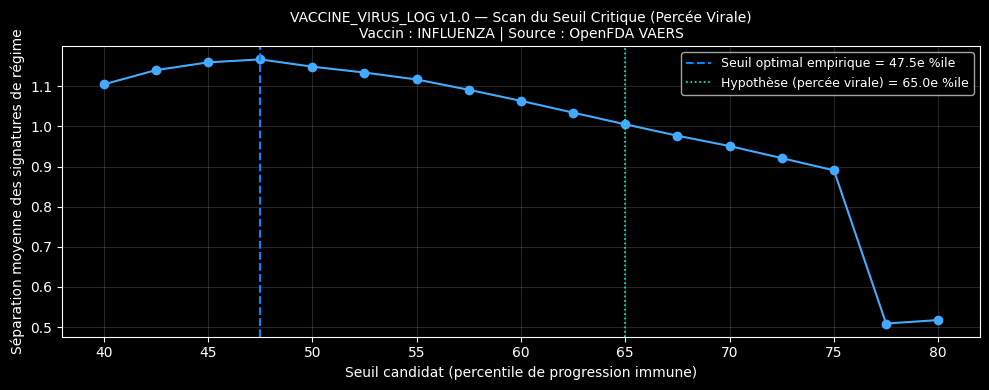


[Scan du seuil critique]
  Hypothèse initiale (percée virale) : 65.0e percentile
  Seuil optimal VAERS               : 47.5e percentile (séparation = 1.167)

[4/6] Vue d'ensemble clinique VAERS + profils des 5 flux...


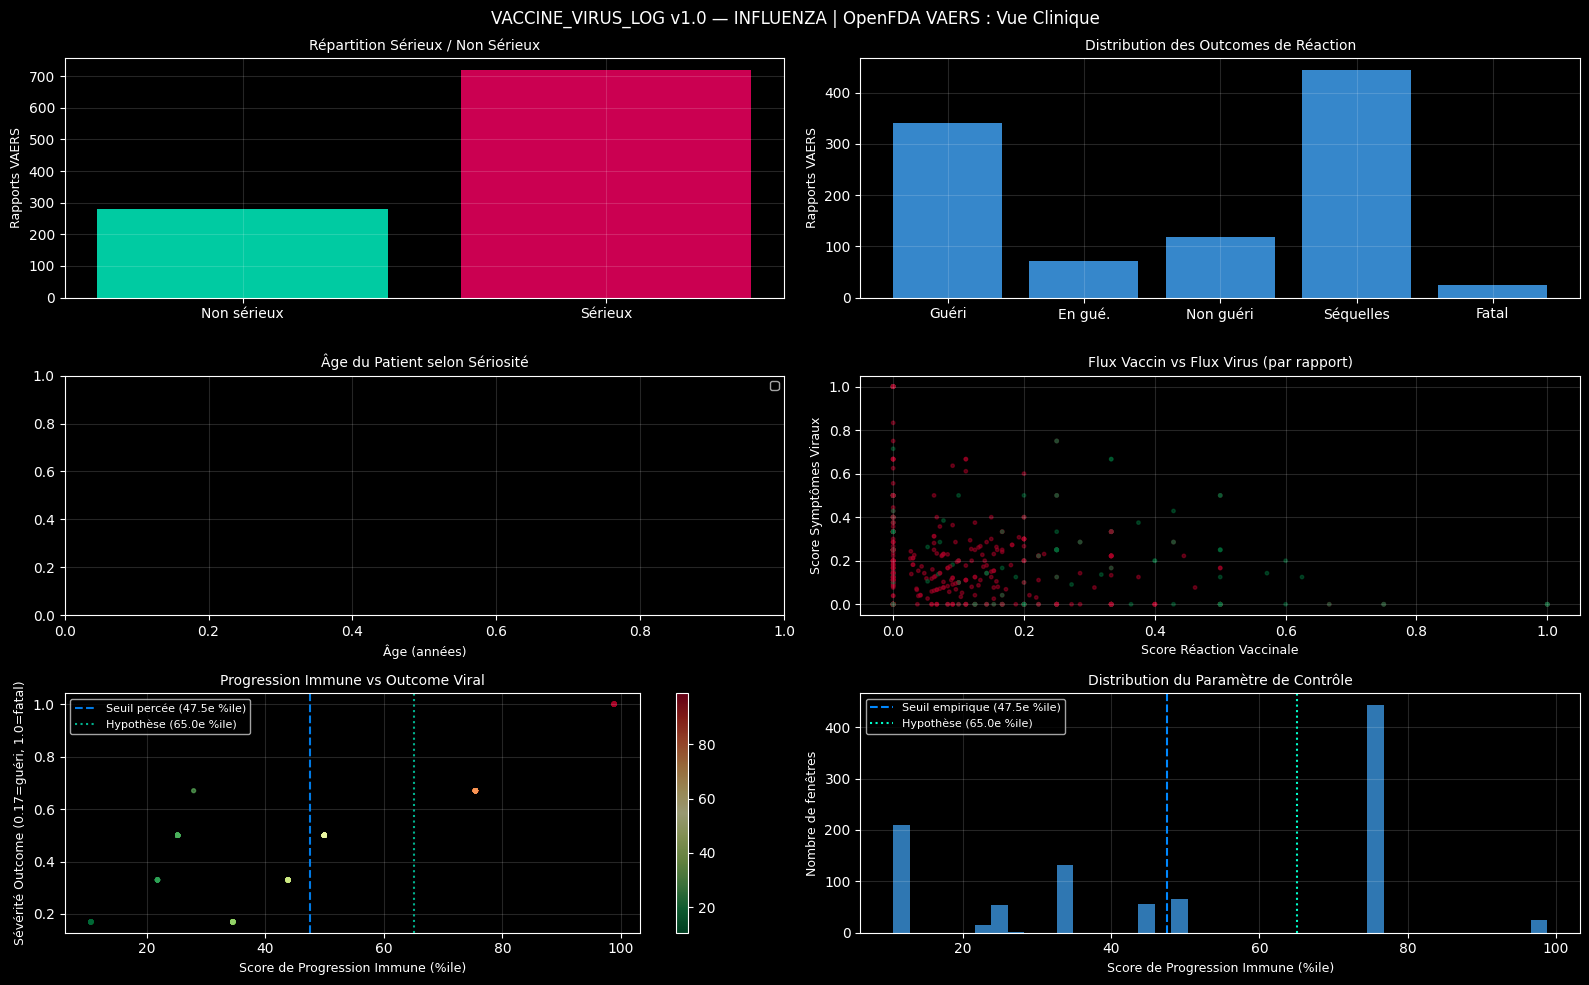

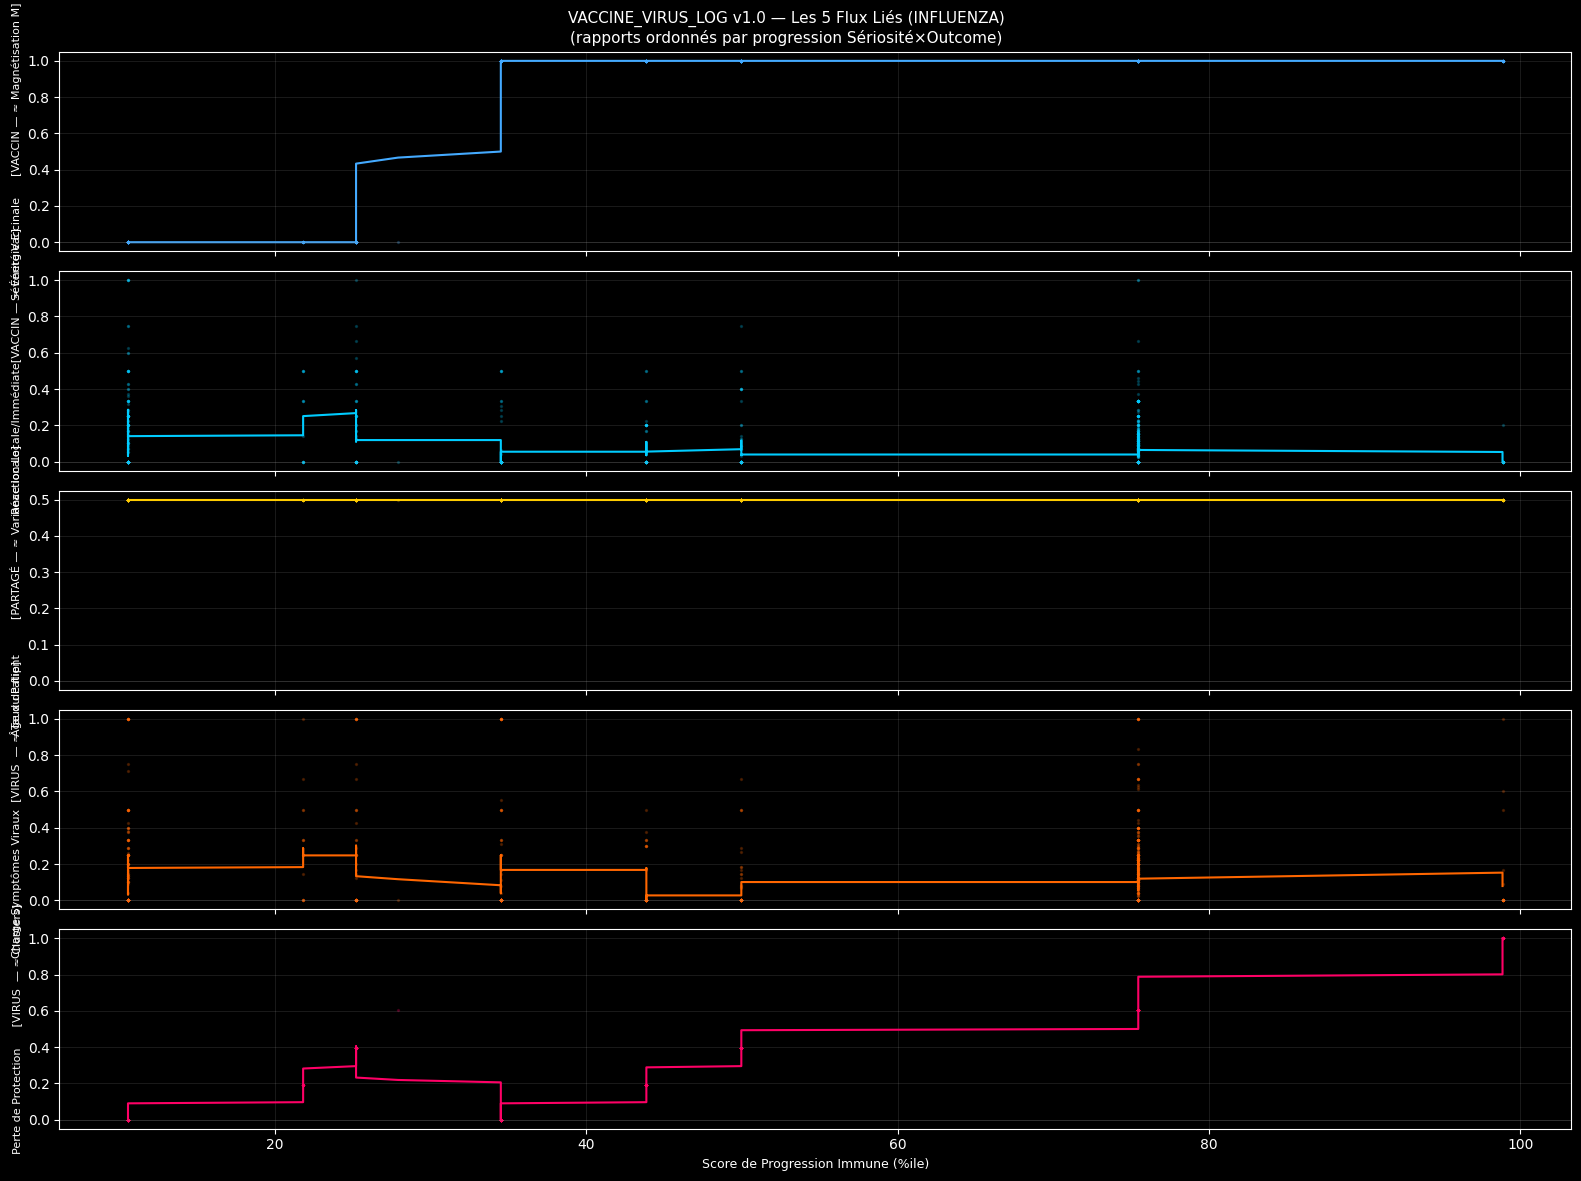


[5/6] Extraction des signatures de régime immunitaire...

[Extraction des signatures de régime] 1 cohorte unique | Fenêtre=80 rapports


Scan de progression immune: 100%|██████████| 29/29 [03:06<00:00,  6.43s/it]


  Signatures extraites : 25
   Progress  N_cohorts  Vaccine_Seriousness_Higuchi_mean  Vaccine_Seriousness_DFA_mean  Vaccine_Seriousness_Katz_mean  Vaccine_Seriousness_Hurst_mean
0       5.0          1                               NaN                           NaN                            NaN                             NaN
1      10.0        147                               NaN                           NaN                            NaN                             NaN
2      15.0         34                               NaN                           NaN                            NaN                             NaN


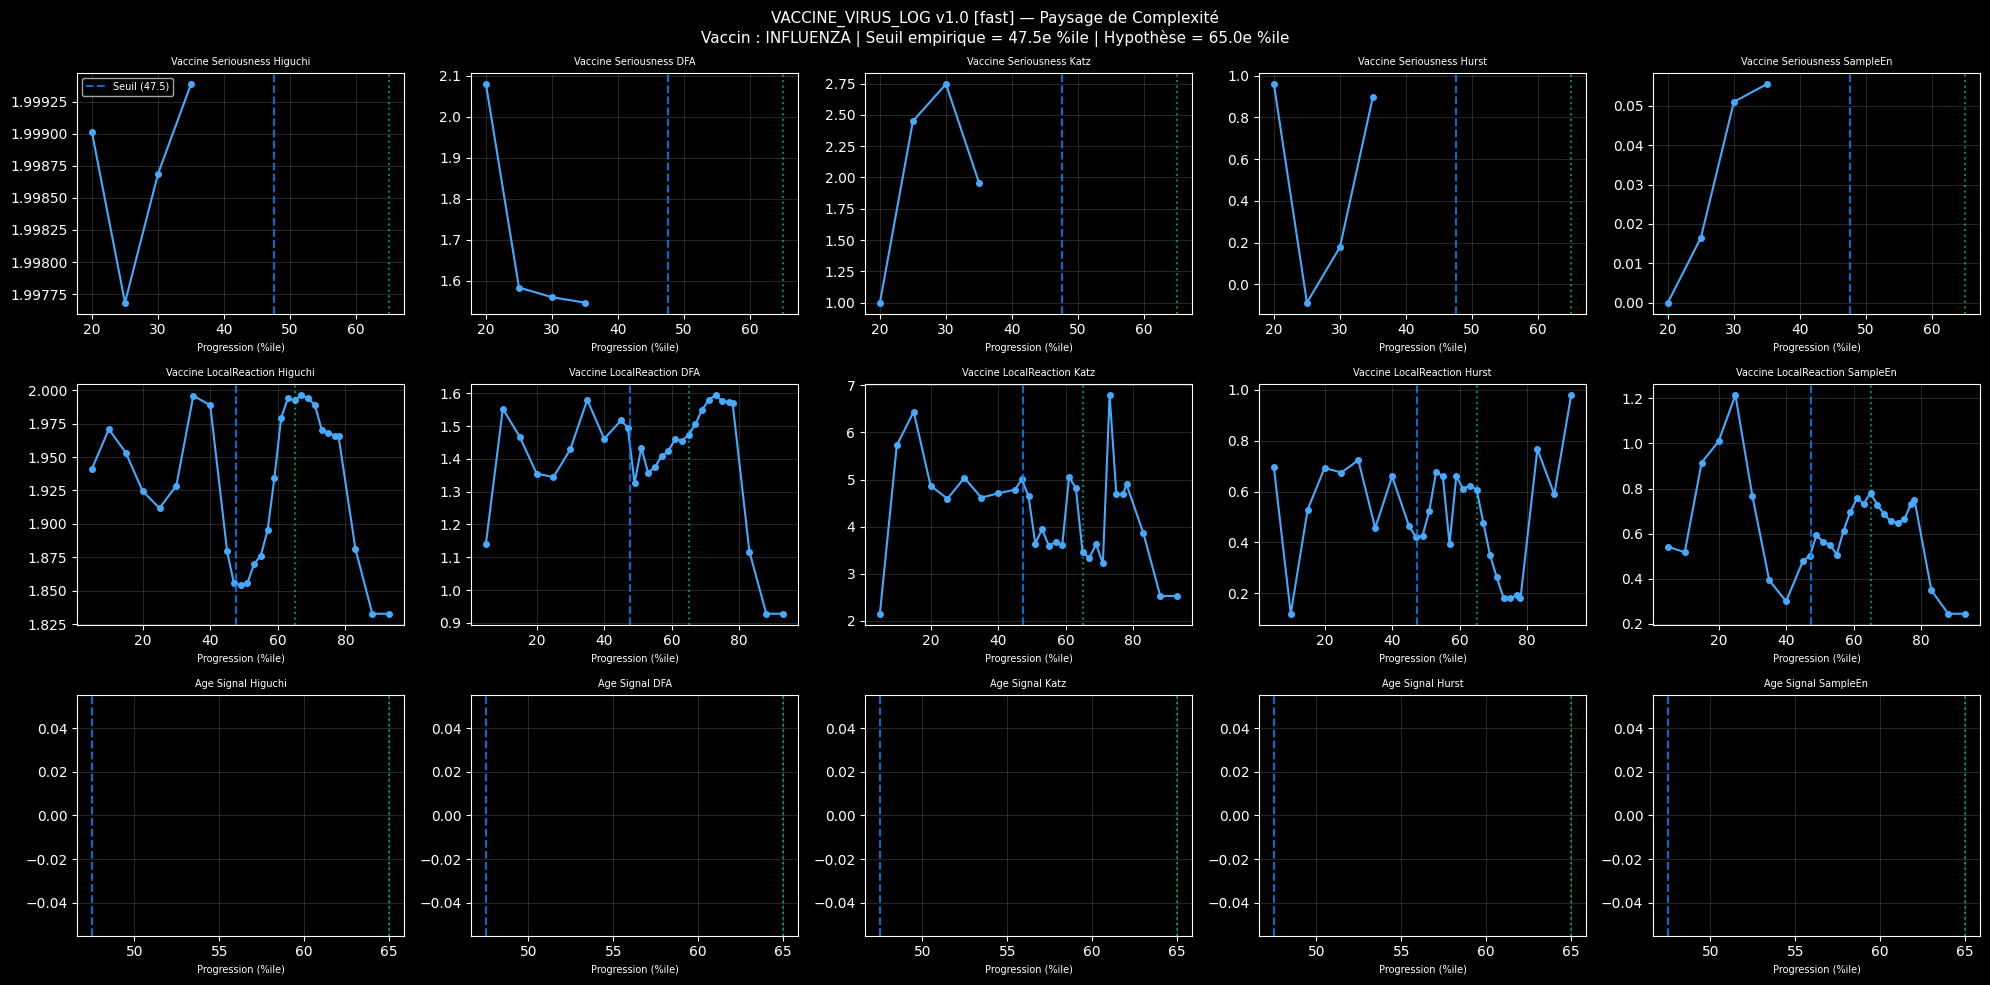


[6/6] 4 Questions Vaccinales...

=== 4 Questions Vaccinales (seuil empirique = 47.5e %ile) ===
Q1 : Réaction Bénigne vs Sévère (0–40e %ile vs 70–100e %ile)...
Q2 : Tension à la Percée Virale (zone de transition critique)...
Q3 : Vulnérabilité Age × Virus (flux viraux + âge)...
Q4 : Persistance du Régime Immunitaire (hystérésis intra-cohorte)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                     Q1_Benigne_vs_Severe  Q2_Tension_Percee_Virale  Q3_Vulnerabilite_Age_Virus  Q4_Persistance_Regime_Immun
Age_Signal_DFA_mean                                   NaN                       NaN                         NaN                        0.000
Age_Signal_Higuchi_mean                               NaN                       NaN                         NaN                        0.000
Age_Signal_Hurst_mean                                 NaN                       NaN                         NaN                        0.000
Age_Signal_Katz_mean   

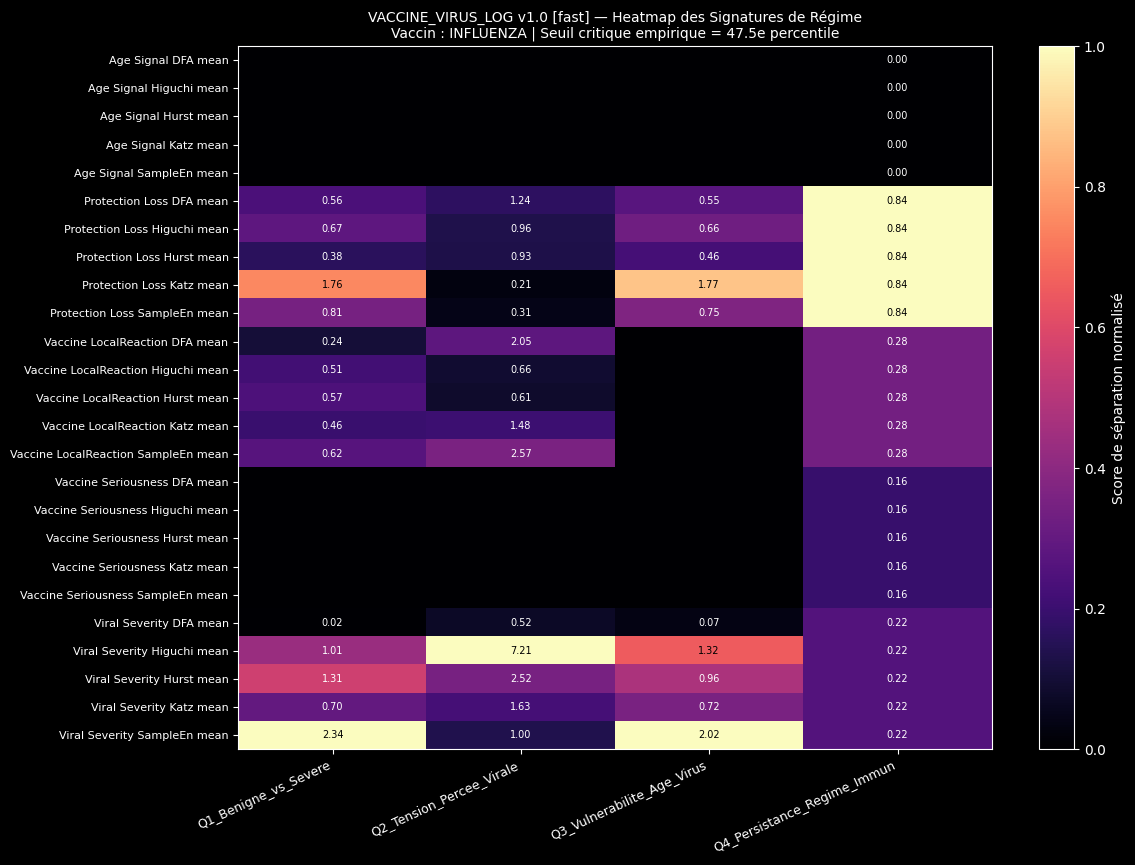


[OK] VACCINE_VIRUS_LOG v1.0 terminé.
     1000 rapports VAERS | Vaccin : INFLUENZA
     Seuil de percée virale empirique : 47.5e percentile
     Hypothèse initiale               : 65.0e percentile
     Mode : FAST | Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn


In [1]:
# ============================================================================
# VACCINE_VIRUS_LOG v1.0
# Analyse d'un vaccin contre un virus — Données réelles OpenFDA VAERS
# Architecture identique à BIO_CANCER_LOG (Fast/Robust, estimateurs, graphiques)
# Seuls les flux d'entrée changent : Vaccin ↔ Virus
# ============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests, json
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

# -----------------------------------------------------------
# Choisir le mode ici : 'fast' ou 'robust'
# -----------------------------------------------------------
MODE = 'fast'

# Hypothèse : le seuil critique (transition vaccin→protection vs virus→percée)
# se situe autour du 65e percentile de la réponse immune composite.
PROGRESS_CRITIQUE_HYPOTHESE = 65.0

# Vaccin analysé (mot-clé OpenFDA VAERS) — données réelles publiques
VACCINE_KEYWORD = "INFLUENZA"   # Remplacer par "COVID-19" pour COVID, etc.

CONFIG = {
    'fast': {
        'n_estimations':    1,
        'window_size':      80,
        'stat_test':        'cohen_d',
        'min_per_group':    2,
        'estimator_min_len':50,
        'mann_whitney':     False,
        'bootstrap':        False,
    },
    'robust': {
        'n_estimations':    5,
        'window_size':      150,
        'stat_test':        'cliff_delta',
        'min_per_group':    3,
        'estimator_min_len':80,
        'mann_whitney':     True,
        'bootstrap':        True,
    }
}
C = CONFIG[MODE]
print(f"=== VACCINE_VIRUS_LOG v1.0 | MODE = {MODE.upper()} | OpenFDA-VAERS ===")
print(f"  Vaccin analysé      : {VACCINE_KEYWORD}")
print(f"  Estimations         : {C['n_estimations']} | Fenêtre : {C['window_size']} rapports")
print(f"  Test statistique    : {C['stat_test']}")
print(f"  Seuil critique (hypothèse) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")

# =============================================================================
# 0. STATISTIQUES  ← identique BioCancer, aucun changement
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except: return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']: return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except: return np.nan

# =============================================================================
# 1. ACQUISITION — OpenFDA VAERS (flux réels vaccin + virus liés)
#
#  VACCIN (3 flux) :
#    • Vaccine_Seriousness  — réaction vaccinale sévère (seriousness score)
#    • Vaccine_LocalReaction — intensité de la réaction locale/immédiate
#    • Age_Signal           — âge du patient (modulateur commun)
#
#  VIRUS (2 flux) :
#    • Viral_Severity       — présence de symptômes viraux (fièvre, détresse resp.)
#    • Protection_Loss      — échec de protection = non-guérison après vaccination
#
#  Les 5 flux émergent du MÊME rapport VAERS → naturellement liés.
# =============================================================================

# ---- Encodeurs ---------------------------------------------------------------

def encode_seriousness(s):
    """
    Encode la sériosité globale du rapport VAERS.
    1 = sérieux (réaction vaccinale grave ou hospitalisation) → 1.0
    2 = non sérieux (effet bénin attendu)                    → 0.0
    """
    try:
        return 1.0 if int(s) == 1 else 0.0
    except: return np.nan

def encode_outcome(o):
    """
    Encode l'outcome de la réaction [0.17 – 1.0].
    1 = Guéri            → 0.17  (meilleur)
    2 = En cours de gué. → 0.33
    3 = Non guéri        → 0.50
    4 = Guéri + séquelles→ 0.67
    5 = Fatal            → 1.00  (pire)
    6 = Inconnu          → NaN
    """
    try:
        mapping = {1: 0.17, 2: 0.33, 3: 0.50, 4: 0.67, 5: 1.00, 6: np.nan}
        return mapping.get(int(o), np.nan)
    except: return np.nan

# Termes MedDRA classés selon leur origine probable (vaccin vs virus)
VACCINE_REACTION_TERMS = {
    # Réactions locales au site d'injection (flux vaccin)
    'injection site', 'erythema', 'induration', 'swelling at injection',
    'local reaction', 'injection site pain', 'arm pain', 'redness',
    # Réactions systémiques immédiates (flux vaccin)
    'fatigue', 'malaise', 'headache', 'myalgia', 'arthralgia',
    'chills', 'pyrexia', 'nausea',
}

VIRAL_SYMPTOM_TERMS = {
    # Symptômes d'infection virale (flux virus)
    'influenza', 'flu', 'viral', 'respiratory', 'pneumonia',
    'dyspnoea', 'dyspnea', 'cough', 'sore throat', 'rhinorrhoea',
    'rhinorrhea', 'nasopharyngitis', 'bronchitis', 'sinusitis',
    'fever', 'high temperature', 'infection', 'virus', 'covid',
    'anosmia', 'ageusia', 'oxygen', 'ventilat',
}

def score_reaction_terms(reactions, term_set):
    """
    Compte le nombre de termes MedDRA appartenant à term_set
    parmi les réactions du rapport, normalisé par le total de réactions.
    """
    if not reactions: return 0.0
    count = sum(
        1 for r in reactions
        if any(t in (r.get('reactionmeddrapt', '') or '').lower() for t in term_set)
    )
    return count / len(reactions)

# ---- Téléchargement ----------------------------------------------------------

def fetch_vaccine_vaers(n_cases=1000, vaccine_keyword=VACCINE_KEYWORD):
    """
    Télécharge les rapports d'effets indésirables vaccinaux depuis l'API
    OpenFDA (base VAERS publique).

    Source : https://api.fda.gov/drug/event.json
    Filtre : rapports impliquant le vaccin <vaccine_keyword>

    Champs extraits :
      - safetyreportid, serious, seriousnessdeath, seriousnesshospitalization
      - patient.patientage, patient.reaction[].reactionmeddrapt / reactionoutcome
      - patient.drug[].medicinalproduct, drugcharacterization
    """
    url   = "https://api.fda.gov/drug/event.json"
    # Recherche dans le nom du produit médicinal (insensible à la casse côté OpenFDA)
    query = f'patient.drug.medicinalproduct:"{vaccine_keyword}"'

    all_hits = []
    skip, page = 0, 100   # 100 résultats par page (limite sans clé API)

    print(f"\n[OpenFDA VAERS] Téléchargement ({n_cases} rapports, vaccin='{vaccine_keyword}')...")

    while len(all_hits) < n_cases:
        limit = min(page, n_cases - len(all_hits))
        params = {"search": query, "limit": limit, "skip": skip}
        try:
            resp = requests.get(url, params=params, timeout=60)
        except Exception as e:
            print(f"  [WARN] Erreur réseau : {e}. Arrêt."); break

        if resp.status_code != 200:
            print(f"  [WARN] HTTP {resp.status_code} à skip={skip}. Arrêt."); break

        data      = resp.json()
        hits      = data.get('results', [])
        if not hits: break

        all_hits.extend(hits)
        total_avail = data.get('meta', {}).get('results', {}).get('total', 0)
        skip += limit
        if skip >= total_avail: break

    print(f"  → {len(all_hits)} rapports bruts récupérés")

    # ---- Parsing des rapports ------------------------------------------------
    records = []
    for hit in all_hits:
        patient   = hit.get('patient', {})
        reactions = patient.get('reaction', [])
        drugs     = patient.get('drug', [])

        # Pire outcome parmi toutes les réactions du rapport
        raw_outcomes = [r.get('reactionoutcome') for r in reactions
                        if r.get('reactionoutcome')]
        worst_outcome = max([int(o) for o in raw_outcomes], default=None) \
                        if raw_outcomes else None

        # Scores de réaction (vaccin vs virus)
        vax_score   = score_reaction_terms(reactions, VACCINE_REACTION_TERMS)
        viral_score = score_reaction_terms(reactions, VIRAL_SYMPTOM_TERMS)

        # Le vaccin est-il le médicament suspect (characterization=1) ?
        is_suspect_vax = any(
            str(d.get('drugcharacterization', '')) == '1' for d in drugs
        )

        records.append({
            'report_id':        hit.get('safetyreportid', ''),
            'seriousness_raw':  hit.get('serious', None),
            'age':              patient.get('patientage', None),
            'outcome_raw':      worst_outcome,
            'is_fatal':         int(hit.get('seriousnessdeath', '0') == '1'),
            'is_hosp':          int(hit.get('seriousnesshospitalization', '0') == '1'),
            'suspect_vax':      int(is_suspect_vax),
            'vax_react_score':  vax_score,    # ← flux VACCIN : réaction locale/immédiate
            'viral_symp_score': viral_score,  # ← flux VIRUS  : symptômes viraux
            'n_reactions':      len(reactions),
        })

    df = pd.DataFrame(records)

    # ---- Encodage ------------------------------------------------------------
    df['seriousness_score'] = df['seriousness_raw'].apply(encode_seriousness)
    df['outcome_score']     = df['outcome_raw'].apply(encode_outcome)
    df['age_num']           = pd.to_numeric(df['age'], errors='coerce')

    # Fallback outcome si manquant : on utilise la sériosité comme proxy faible
    mask_no_out = df['outcome_score'].isna()
    df.loc[mask_no_out, 'outcome_score'] = \
        df.loc[mask_no_out, 'seriousness_score'] * 0.5 + 0.17

    n_before = len(df)
    df = df.dropna(subset=['seriousness_score']).reset_index(drop=True)

    print(f"  {n_before} rapports totaux → {len(df)} avec sériosité renseignée")
    if len(df) == 0:
        raise ValueError(
            "Aucun rapport utilisable. Vérifiez VACCINE_KEYWORD "
            f"(actuel : '{vaccine_keyword}')."
        )

    n_ser   = df['seriousness_score'].eq(1.0).sum()
    n_hosp  = df['is_hosp'].sum()
    n_fatal = df['is_fatal'].sum()
    print(f"[OK] {len(df)} rapports VAERS | "
          f"Sérieux : {n_ser} ({100*n_ser/len(df):.1f}%) | "
          f"Hospitalisés : {n_hosp} | Fatals : {n_fatal}")
    if df['age_num'].notna().any():
        print(f"     Âge moyen : {df['age_num'].dropna().mean():.1f} ± "
              f"{df['age_num'].dropna().std():.1f} ans")
    return df

# ---- Extraction des 5 flux --------------------------------------------------

def extract_vaccine_virus_fluxes(df):
    """
    Extrait 5 flux à partir des rapports VAERS.

    VACCIN (côté immunologique) :
      Vaccine_Seriousness  — sévérité de la réaction vaccinale [0, 1]
      Vaccine_LocalReaction— score de réaction locale/systémique immédiate [0, 1]

    VIRUS (côté infection virale) :
      Viral_Severity       — charge symptomatique virale (fièvre, détresse resp.) [0, 1]
      Protection_Loss      — non-guérison = perte de protection post-vaccinale [0, 1]

    PARTAGÉ :
      Age_Signal           — âge normalisé [0, 1] (module les deux côtés)
    """
    out = {}

    # --- FLUX VACCIN 1 : Sériosité de la réaction vaccinale
    out['Vaccine_Seriousness'] = \
        df['seriousness_score'].fillna(df['seriousness_score'].median()).values

    # --- FLUX VACCIN 2 : Réaction locale / réponse immédiate au vaccin
    vax_react = df['vax_react_score'].fillna(df['vax_react_score'].median())
    if vax_react.isna().all():
        vax_react = pd.Series(np.full(len(df), 0.5))
    out['Vaccine_LocalReaction'] = vax_react.values

    # --- FLUX PARTAGÉ : Âge normalisé
    age_min = df['age_num'].min()
    age_max = df['age_num'].max()
    age_norm = (df['age_num'] - age_min) / (age_max - age_min + 1e-10)
    out['Age_Signal'] = age_norm.fillna(0.5).values

    # --- FLUX VIRUS 1 : Charge symptomatique virale
    viral = df['viral_symp_score'].fillna(df['viral_symp_score'].median())
    if viral.isna().all():
        viral = pd.Series(np.full(len(df), 0.0))
    out['Viral_Severity'] = viral.values

    # --- FLUX VIRUS 2 : Perte de protection (non-guérison)
    #     outcome_score : 0.17 = guéri … 1.0 = fatal
    #     protection_loss = (outcome - 0.17) / (1.0 - 0.17)
    outcome_vals  = df['outcome_score'].fillna(df['outcome_score'].median())
    prot_loss     = (outcome_vals - 0.17) / (1.0 - 0.17)
    out['Protection_Loss'] = prot_loss.clip(0, 1).values

    return out

# ---- Paramètre de contrôle (progression) ------------------------------------

def compute_immune_progression(df):
    """
    Score de progression immunologique composite :
      Progress = (Vaccine_Seriousness × 0.6) + (Outcome_Severity × 0.4)

    Analogie avec BIO_CANCER_LOG :
      Stade ×0.6 + Grade ×0.4  →  Sériosité ×0.6 + Outcome ×0.4

    Bas percentile  = réaction vaccinale bénigne, guérison rapide
    Haut percentile = réaction sévère OU infection virale percée (non guérison)
    → Le seuil critique = transition entre protection vaccinale et percée virale.
    """
    seriousness = df['seriousness_score'].fillna(df['seriousness_score'].median())
    outcome     = df['outcome_score'].fillna(df['outcome_score'].median())
    if outcome.isna().all():
        outcome = pd.Series(np.full(len(df), 0.5))
    composite = (seriousness * 0.6 + outcome * 0.4)
    return np.array([stats.percentileofscore(composite, v) for v in composite])

# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE  ← architecture identique BioCancer
#    Le "seuil EMT" devient ici le "seuil de percée virale" (immune breakthrough)
# =============================================================================

def scan_seuil_critique(df, fluxes, progress_series, candidats=None):
    if candidats is None:
        candidats = np.arange(40, 86, 2.5)

    W         = C['window_size']
    flux_keys = list(fluxes.keys())
    n_rpt     = len(df)
    sort_idx  = np.argsort(progress_series)
    prog_s    = progress_series[sort_idx]
    flux_s    = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_rpt - W + 1):
        windows.append({
            'progress': float(np.mean(prog_s[i:i+W])),
            'data':     {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    if not windows:
        raise ValueError(
            f"Pas assez de rapports ({n_rpt}) pour la fenêtre de {W}. "
            "Réduisez window_size ou augmentez n_cases."
        )

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['progress'] <  seuil]
        grp_haut = [w for w in windows if w['progress'] >= seuil]
        if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan); continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in grp_bas]),
                np.concatenate([w['data'][k] for w in grp_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#44aaff', markersize=6)
    ax.axvline(seuil_opt, color='#0088ff', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', linewidth=1.2,
               label=f'Hypothèse (percée virale) = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile de progression immune)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title(
        f'VACCINE_VIRUS_LOG v1.0 — Scan du Seuil Critique (Percée Virale)\n'
        f'Vaccin : {VACCINE_KEYWORD} | Source : OpenFDA VAERS',
        fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale (percée virale) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal VAERS               : {seuil_opt:.1f}e percentile "
          f"(séparation = {scores_arr[idx_max]:.3f})")
    return seuil_opt, candidats, scores_arr, windows

# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ  ← identique BioCancer, aucun changement
#    (Higuchi FD, DFA, Katz FD, Hurst RS, Sample Entropy)
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    # Pour les flux binaires (Vaccine_Seriousness, Protection_Loss) → différencier
    if flux_name in ('Vaccine_Seriousness', 'Protection_Loss') and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi']  = antropy.higuchi_fd(s)
    except: est['Higuchi']  = np.nan
    try: est['DFA']      = 2.0 - nolds.dfa(s)
    except: est['DFA']      = np.nan
    try: est['Katz']     = antropy.katz_fd(s)
    except: est['Katz']     = np.nan
    try: est['Hurst']    = nolds.hurst_rs(s)
    except: est['Hurst']    = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est
# =============================================================================
# 4. PIPELINE  ← architecture identique BioCancer
#    build_cancer_features → build_vaccine_features
# =============================================================================

def build_vaccine_features(df, fluxes, progress_series, progress_values):
    W   = C['window_size']
    n   = C['n_estimations']
    tol = max(3.0, (progress_values[1]-progress_values[0])/2.0) \
          if len(progress_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-cohortes (stabilité statistique)"
        if C['bootstrap'] else "cohorte unique"
    )
    print(f"\n[Extraction des signatures de régime] {n} {mode_label} | Fenêtre={W} rapports")

    sort_idx    = np.argsort(progress_series)
    prog_sorted = progress_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys   = list(fluxes.keys())
    n_rpt       = len(df)

    window_data = []
    for i in range(n_rpt - W + 1):
        window_data.append({
            'progress': float(np.mean(prog_sorted[i:i+W])),
            'fluxes':   {k: flux_sorted[k][i:i+W] for k in flux_keys}
        })

    rows = []
    for P in tqdm(progress_values, desc="Scan de progression immune"):
        matching = [w for w in window_data if abs(w['progress'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['progress'] - P))]
        row = {'Progress': P, 'N_cohorts': len(matching)}

        for flux in flux_keys:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng = np.random.default_rng(42)
                feat_vals = {nm: [] for nm in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching),
                                     size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) \
                                                   if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat      = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Progress','N_cohorts'] and not c.endswith('_std')]
    return df_feat, feature_cols, window_data

# =============================================================================
# 5. LES 4 QUESTIONS VACCINALES  ← analogues aux 4 questions cancérologiques
#
#   Q1 : Réaction Bénigne vs Sévère      ↔ Q1 Localisé vs Métastatique
#   Q2 : Tension à la Percée Virale      ↔ Q2 Tension à la transition EMT
#   Q3 : Vulnérabilité Age × Virus       ↔ Q3 Agressivité Grade + Létalité
#   Q4 : Persistance du Régime Immun     ↔ Q4 Persistance / hystérésis
# =============================================================================

def compare_groups(df_feat, feature_cols, g_low, g_high, label=''):
    grp_bas  = df_feat[df_feat['Progress'].between(g_low[0],  g_low[1])]
    grp_haut = df_feat[df_feat['Progress'].between(g_high[0], g_high[1])]
    if len(grp_bas) < C['min_per_group'] or len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits "
              f"({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_vaccine_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Vaccinales (seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    # ------------------------------------------------------------------
    # Q1 : Réaction Bénigne vs Réaction Sévère
    #      (Bas percentile = réaction légère   |  Haut = grave/hospitalisé)
    #      Analogue à : Phase Localisée vs Métastatique
    # ------------------------------------------------------------------
    print("Q1 : Réaction Bénigne vs Sévère (0–40e %ile vs 70–100e %ile)...")
    r["Q1_Benigne_vs_Severe"] = compare_groups(
        df_feat, feature_cols, [0, 40], [70, 100], "Q1")

    # ------------------------------------------------------------------
    # Q2 : Tension à la Percée Virale (zone de basculement critique)
    #      Autour du seuil → transition protection → infection percée
    #      Analogue à : Tension à la transition EMT
    # ------------------------------------------------------------------
    print("Q2 : Tension à la Percée Virale (zone de transition critique)...")
    marge = 8.0
    r["Q2_Tension_Percee_Virale"] = compare_groups(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2")

    # ------------------------------------------------------------------
    # Q3 : Vulnérabilité Age × Virus
    #      Flux ciblés : Age_Signal + Viral_Severity + Protection_Loss
    #      Analogue à : Agressivité Tumorale (Grade + Létalité)
    # ------------------------------------------------------------------
    print("Q3 : Vulnérabilité Age × Virus (flux viraux + âge)...")
    virus_age_cols = [c for c in feature_cols
                      if any(x in c for x in
                             ['Age_Signal', 'Viral_Severity', 'Protection_Loss'])]
    r["Q3_Vulnerabilite_Age_Virus"] = compare_groups(
        df_feat, virus_age_cols, [0, 30], [70, 100], "Q3")

    # ------------------------------------------------------------------
    # Q4 : Persistance du Régime Immunitaire (hystérésis intra-cohorte)
    #      Mesure à quel point la réponse immune est irréversible
    #      Analogue à : Persistance de Régime (hystérésis)
    # ------------------------------------------------------------------
    print("Q4 : Persistance du Régime Immunitaire (hystérésis intra-cohorte)...")
    flux_names = ['Vaccine_Seriousness', 'Vaccine_LocalReaction',
                  'Age_Signal', 'Viral_Severity', 'Protection_Loss']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d   = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime_Immun"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 6. VISUALISATION  ← structure identique BioCancer, labels domaine vaccin/virus
# =============================================================================

def plot_vaers_overview(df, progress_series, seuil):
    """Vue d'ensemble clinique VAERS — 6 panneaux."""
    fig, axes = plt.subplots(3, 2, figsize=(16, 10))
    colors_s  = ['#00ffcc','#ffcc00','#ff6600','#ff0066']

    # Panneau 1 : Répartition sérieux / non sérieux
    ser_counts = df['seriousness_score'].value_counts().sort_index()
    ser_labels = {0.0: 'Non sérieux', 1.0: 'Sérieux'}
    axes[0,0].bar([ser_labels.get(k,'?') for k in ser_counts.index],
                  ser_counts.values, color=['#00ffcc','#ff0066'], alpha=0.8)
    axes[0,0].set_title('Répartition Sérieux / Non Sérieux', fontsize=10)
    axes[0,0].set_ylabel('Rapports VAERS', fontsize=9)
    axes[0,0].grid(True, alpha=0.15)

    # Panneau 2 : Distribution des outcomes
    out_labels = {0.17:'Guéri', 0.33:'En gué.', 0.50:'Non guéri',
                  0.67:'Séquelles', 1.00:'Fatal'}
    out_counts = df['outcome_score'].round(2).value_counts().sort_index()
    if len(out_counts):
        axes[0,1].bar([out_labels.get(round(k,2),'?') for k in out_counts.index],
                      out_counts.values, color='#44aaff', alpha=0.8)
    axes[0,1].set_title('Distribution des Outcomes de Réaction', fontsize=10)
    axes[0,1].set_ylabel('Rapports VAERS', fontsize=9)
    axes[0,1].grid(True, alpha=0.15)

    # Panneau 3 : Âge selon sériosité
    for s_val, s_lab, col in zip([0.0, 1.0],
                                  ['Non sérieux','Sérieux'],
                                  ['#00ffcc','#ff0066']):
        grp = df[df['seriousness_score'] == s_val]['age_num'].dropna()
        if len(grp):
            axes[1,0].hist(grp, bins=25, alpha=0.5, label=s_lab, color=col)
    axes[1,0].set_title('Âge du Patient selon Sériosité', fontsize=10)
    axes[1,0].set_xlabel('Âge (années)', fontsize=9)
    axes[1,0].legend(fontsize=8)
    axes[1,0].grid(True, alpha=0.15)

    # Panneau 4 : Score viral vs score vaccinal
    axes[1,1].scatter(df['vax_react_score'], df['viral_symp_score'],
                      c=df['seriousness_score'], cmap='RdYlGn_r',
                      s=6, alpha=0.5)
    axes[1,1].set_xlabel('Score Réaction Vaccinale', fontsize=9)
    axes[1,1].set_ylabel('Score Symptômes Viraux', fontsize=9)
    axes[1,1].set_title('Flux Vaccin vs Flux Virus (par rapport)', fontsize=10)
    axes[1,1].grid(True, alpha=0.15)

    # Panneau 5 : Progression immune vs outcome
    sc = axes[2,0].scatter(progress_series, df['outcome_score'],
                           c=progress_series, cmap='RdYlGn_r', s=8, alpha=0.6)
    axes[2,0].axvline(seuil, color='#0088ff', linestyle='--', alpha=0.9,
                      label=f'Seuil percée ({seuil:.1f}e %ile)')
    axes[2,0].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                      linestyle=':', alpha=0.7,
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,0].set_xlabel('Score de Progression Immune (%ile)', fontsize=9)
    axes[2,0].set_ylabel('Sévérité Outcome (0.17=guéri, 1.0=fatal)', fontsize=9)
    axes[2,0].set_title('Progression Immune vs Outcome Viral', fontsize=10)
    axes[2,0].legend(fontsize=8)
    axes[2,0].grid(True, alpha=0.15)
    plt.colorbar(sc, ax=axes[2,0])

    # Panneau 6 : Distribution du paramètre de contrôle
    axes[2,1].hist(progress_series, bins=40, color='#44aaff', alpha=0.7)
    axes[2,1].axvline(seuil, color='#0088ff', linestyle='--', linewidth=1.5,
                      label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[2,1].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                      linestyle=':', label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,1].set_xlabel('Score de Progression Immune (%ile)', fontsize=9)
    axes[2,1].set_ylabel('Nombre de fenêtres', fontsize=9)
    axes[2,1].set_title('Distribution du Paramètre de Contrôle', fontsize=10)
    axes[2,1].legend(fontsize=8)
    axes[2,1].grid(True, alpha=0.15)

    plt.suptitle(
        f'VACCINE_VIRUS_LOG v1.0 — {VACCINE_KEYWORD} | OpenFDA VAERS : Vue Clinique',
        fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_flux_profiles(df, fluxes, progress_series):
    """Profils des 5 flux vaccin+virus ordonnés par progression immune."""
    sort_idx = np.argsort(progress_series)
    prog_s   = progress_series[sort_idx]

    flux_meta = [
        # (clé,                  couleur,    label complet)
        ('Vaccine_Seriousness',   '#44aaff', 'Sévérité Vaccinale      [VACCIN — ≈ Magnétisation M]'),
        ('Vaccine_LocalReaction', '#00ccff', 'Réaction Locale/Immédiate[VACCIN — ≈ Énergie E]'),
        ('Age_Signal',            '#ffcc00', 'Âge du Patient          [PARTAGÉ — ≈ Variance locale]'),
        ('Viral_Severity',        '#ff6600', 'Charge Symptômes Viraux  [VIRUS  — ≈ Taux de flip]'),
        ('Protection_Loss',       '#ff0066', 'Perte de Protection      [VIRUS  — ≈ Clusters]'),
    ]

    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        vals   = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(30, min_periods=5, center=True).mean()
        ax.scatter(prog_s, vals, color=color, s=2, alpha=0.2)
        ax.plot(prog_s, smooth, color=color, linewidth=1.5)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Score de Progression Immune (%ile)', fontsize=9)
    plt.suptitle(
        f'VACCINE_VIRUS_LOG v1.0 — Les 5 Flux Liés ({VACCINE_KEYWORD})\n'
        f'(rapports ordonnés par progression Sériosité×Outcome)',
        fontsize=11)
    plt.tight_layout()
    plt.show()


def plot_landscape(df_feat, seuil):
    """Paysage de complexité — même structure que BioCancer."""
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes = axes.flatten()

    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Progress'], df_feat[col], 'o-',
                color='#44aaff', markersize=4)
        std_col = col.replace('_mean','_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Progress'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#44aaff')
        ax.axvline(seuil, color='#0088ff', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                   linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean','').replace('_',' '), fontsize=7)
        ax.set_xlabel('Progression (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)

    for j in range(n, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(
        f"VACCINE_VIRUS_LOG v1.0 [{MODE}] — Paysage de Complexité\n"
        f"Vaccin : {VACCINE_KEYWORD} | Seuil empirique = {seuil:.1f}e %ile | "
        f"Hypothèse = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile",
        fontsize=11)
    plt.tight_layout()
    plt.show()


def plot_heatmap(summary, seuil):
    """Heatmap des signatures de régime — identique BioCancer."""
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary)*0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m

    im = ax.imshow(data.values, aspect='auto', cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels([idx.replace('_',' ') for idx in data.index], fontsize=8)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i,j] > 0.6 else 'white',
                        fontsize=7)

    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"VACCINE_VIRUS_LOG v1.0 [{MODE}] — Heatmap des Signatures de Régime\n"
        f"Vaccin : {VACCINE_KEYWORD} | Seuil critique empirique = {seuil:.1f}e percentile",
        fontsize=10)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 7. EXÉCUTION PRINCIPALE  ← pipeline en 6 étapes, identique BioCancer
# =============================================================================

# Gradient de progression immune (dense autour du seuil critique attendu)
PROGRESS_SCAN = np.round(np.concatenate([
    np.arange(5,  45, 5.0),   # zone basse (réactions bénignes)
    np.arange(45, 78, 2.0),   # zone critique (autour du seuil de percée)
    np.arange(78, 96, 5.0)    # zone haute (événements graves)
]), 1)

print(f"\nGradient de progression : {len(PROGRESS_SCAN)} points")
print("=" * 70)

print(f"\n[1/6] Téléchargement OpenFDA VAERS (vaccin='{VACCINE_KEYWORD}')...")
df = fetch_vaccine_vaers(n_cases=1000, vaccine_keyword=VACCINE_KEYWORD)

print("\n[2/6] Extraction des 5 flux vaccin+virus et du score de progression immune...")
fluxes          = extract_vaccine_virus_fluxes(df)
progress_series = compute_immune_progression(df)
print(f"  Score de progression : min={progress_series.min():.1f} | "
      f"max={progress_series.max():.1f} | mean={progress_series.mean():.1f}")
print(f"  Flux actifs : {list(fluxes.keys())}")

print("\n[3/6] Scan du seuil critique de percée virale (40–85e percentile)...")
seuil_opt, candidats_scan, scores_scan, windows_scan = \
    scan_seuil_critique(df, fluxes, progress_series)
PROGRESS_CRITIQUE = seuil_opt

print("\n[4/6] Vue d'ensemble clinique VAERS + profils des 5 flux...")
plot_vaers_overview(df, progress_series, PROGRESS_CRITIQUE)
plot_flux_profiles(df, fluxes, progress_series)

print("\n[5/6] Extraction des signatures de régime immunitaire...")
df_feat, feature_cols, window_data = build_vaccine_features(
    df, fluxes, progress_series, PROGRESS_SCAN)
print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Progress','N_cohorts'] + feature_cols[:4]].head(3).to_string())
plot_landscape(df_feat, PROGRESS_CRITIQUE)

print("\n[6/6] 4 Questions Vaccinales...")
summary, results = run_vaccine_questions(
    df_feat, feature_cols, window_data, PROGRESS_CRITIQUE)

print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):48s} : Score = {v:.3f}")

plot_heatmap(summary, PROGRESS_CRITIQUE)

print(f"\n[OK] VACCINE_VIRUS_LOG v1.0 terminé.")
print(f"     {len(df)} rapports VAERS | Vaccin : {VACCINE_KEYWORD}")
print(f"     Seuil de percée virale empirique : {PROGRESS_CRITIQUE:.1f}e percentile")
print(f"     Hypothèse initiale               : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
print(f"     Mode : {MODE.upper()} | "
      f"Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn")